# Prueba Técnica – Enunciado

## CASO TÉCNICO – CIENTÍFICO DE DATOS | ANALÍTICA AVANZADA

## Contexto Institucional

La Universidad Siglo 21 monitorea periódicamente la experiencia de sus estudiantes mediante distintos indicadores de satisfacción y fidelización.

Uno de los principales indicadores estratégicos es el **Net Promoter Score (NPS)**, utilizado para medir la disposición de los estudiantes a recomendar la institución.

El NPS es un KPI de seguimiento ejecutivo utilizado por distintas áreas de gestión para evaluar la evolución de la experiencia estudiantil y apoyar la toma de decisiones.

Complementariamente, se monitorean distintos atributos de experiencia (drivers) que permiten comprender los factores asociados a la evolución del indicador.

La Dirección solicita construir una propuesta metodológica para proyectar el comportamiento futuro del NPS y generar escenarios que ayuden en la planificación institucional.

## Consigna

### Parte 1. Realizar un análisis exploratorio del dataset.

### 1.1 Lectura del dataset

In [1]:
import pandas as pd

pd.set_option("display.float_format", "{:.2f}".format)

ruta_dataset = "dataset/DS_historico NPS + DRIVERS.csv"

df_nps = pd.read_csv(ruta_dataset, sep=";")

print(df_nps.shape)

df_nps.head()

(51, 6)


,ANO_MES,NPS,Driver_A,Driver_B,Driver_C,Driver_D
0,1/1/2021,44,68,86,78,67
1,1/2/2021,65,70,86,85,74
2,1/3/2021,54,71,86,86,76
3,1/4/2021,48,68,84,81,69
4,1/5/2021,64,73,90,87,93


### 1.2 Tipos de datos y granularidad

In [2]:
df_nps.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51 entries, 0 to 50
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   ANO_MES   51 non-null     object
 1   NPS       51 non-null     int64 
 2   Driver_A  51 non-null     int64 
 3   Driver_B  51 non-null     int64 
 4   Driver_C  51 non-null     int64 
 5   Driver_D  51 non-null     int64 
dtypes: int64(5), object(1)
memory usage: 2.5+ KB


In [3]:
df_nps["ANO_MES"] = pd.to_datetime(
    df_nps["ANO_MES"],
    format="%d/%m/%Y"
)
df_nps["ANO_MES"].dtype

dtype('<M8[ns]')

In [4]:
df_nps.ANO_MES.min(), df_nps.ANO_MES.max()

(Timestamp('2021-01-01 00:00:00'), Timestamp('2025-03-01 00:00:00'))

**Conclusiones de los escenarios**

- La trayectoria **Base** utiliza Naive estacional como referencia, por lo que conserva las variaciones mensuales observadas.
- El escenario **Pesimista** se obtiene aplicando un ajuste negativo sobre esa referencia cuando los drivers empeoran.
- El escenario **Optimista** aplica un ajuste positivo cuando los drivers evolucionan favorablemente.
- Ridge y SARIMAX se utilizan para estimar el ajuste asociado a los drivers; no reemplazan la proyección base de Naive estacional.

**Implicancia para el negocio:** la proyección base ofrece una expectativa dinámica y los otros escenarios permiten anticipar riesgos, definir metas y preparar acciones diferenciadas.

### 1.3 Calidad de datos: nulos, duplicados y valores únicos

In [5]:
# Nulos
df_nps.isnull().sum()/len(df_nps)*100

ANO_MES    0.00
NPS        0.00
Driver_A   0.00
Driver_B   0.00
Driver_C   0.00
Driver_D   0.00
dtype: float64

Conviene chequear los duplicados principalmente a nivel de la unidad de análisis, es decir, en `ANO_MES`, porque debería existir una sola observación por mes.

In [6]:
df_nps[df_nps.duplicated(subset=["ANO_MES"], keep=False)]

,ANO_MES,NPS,Driver_A,Driver_B,Driver_C,Driver_D


También podemos verificar si existen filas completamente duplicadas:

In [7]:
df_nps.duplicated().sum()

0

In [8]:
df_nps.nunique()

ANO_MES     51
NPS         28
Driver_A    26
Driver_B    23
Driver_C    17
Driver_D    18
dtype: int64

**Conclusiones de los escenarios**

- La trayectoria **Base** utiliza Naive estacional como referencia, por lo que conserva las variaciones mensuales observadas.
- El escenario **Pesimista** se obtiene aplicando un ajuste negativo sobre esa referencia cuando los drivers empeoran.
- El escenario **Optimista** aplica un ajuste positivo cuando los drivers evolucionan favorablemente.
- Ridge y SARIMAX se utilizan para estimar el ajuste asociado a los drivers; no reemplazan la proyección base de Naive estacional.

**Implicancia para el negocio:** la proyección base ofrece una expectativa dinámica y los otros escenarios permiten anticipar riesgos, definir metas y preparar acciones diferenciadas.

### 1.4 Análisis univariado

#### 1.4.1 Estadísticas descriptivas

In [9]:
df_nps.describe(include="number").T

,count,mean,std,min,25%,50%,75%,max
NPS,51.00,46.55,9.93,24.00,41.50,47.00,52.00,73.00
Driver_A,51.00,74.53,11.32,58.00,64.00,73.00,85.00,93.00
Driver_B,51.00,83.63,6.44,72.00,78.50,83.00,87.50,96.00
Driver_C,51.00,82.49,4.51,73.00,80.00,82.00,85.00,95.00
Driver_D,51.00,84.18,5.60,67.00,81.00,85.00,88.00,99.00


**Conclusiones de los escenarios**

- La trayectoria **Base** utiliza Naive estacional como referencia, por lo que conserva las variaciones mensuales observadas.
- El escenario **Pesimista** se obtiene aplicando un ajuste negativo sobre esa referencia cuando los drivers empeoran.
- El escenario **Optimista** aplica un ajuste positivo cuando los drivers evolucionan favorablemente.
- Ridge y SARIMAX se utilizan para estimar el ajuste asociado a los drivers; no reemplazan la proyección base de Naive estacional.

**Implicancia para el negocio:** la proyección base ofrece una expectativa dinámica y los otros escenarios permiten anticipar riesgos, definir metas y preparar acciones diferenciadas.

#### 1.4.2 Distribuciones

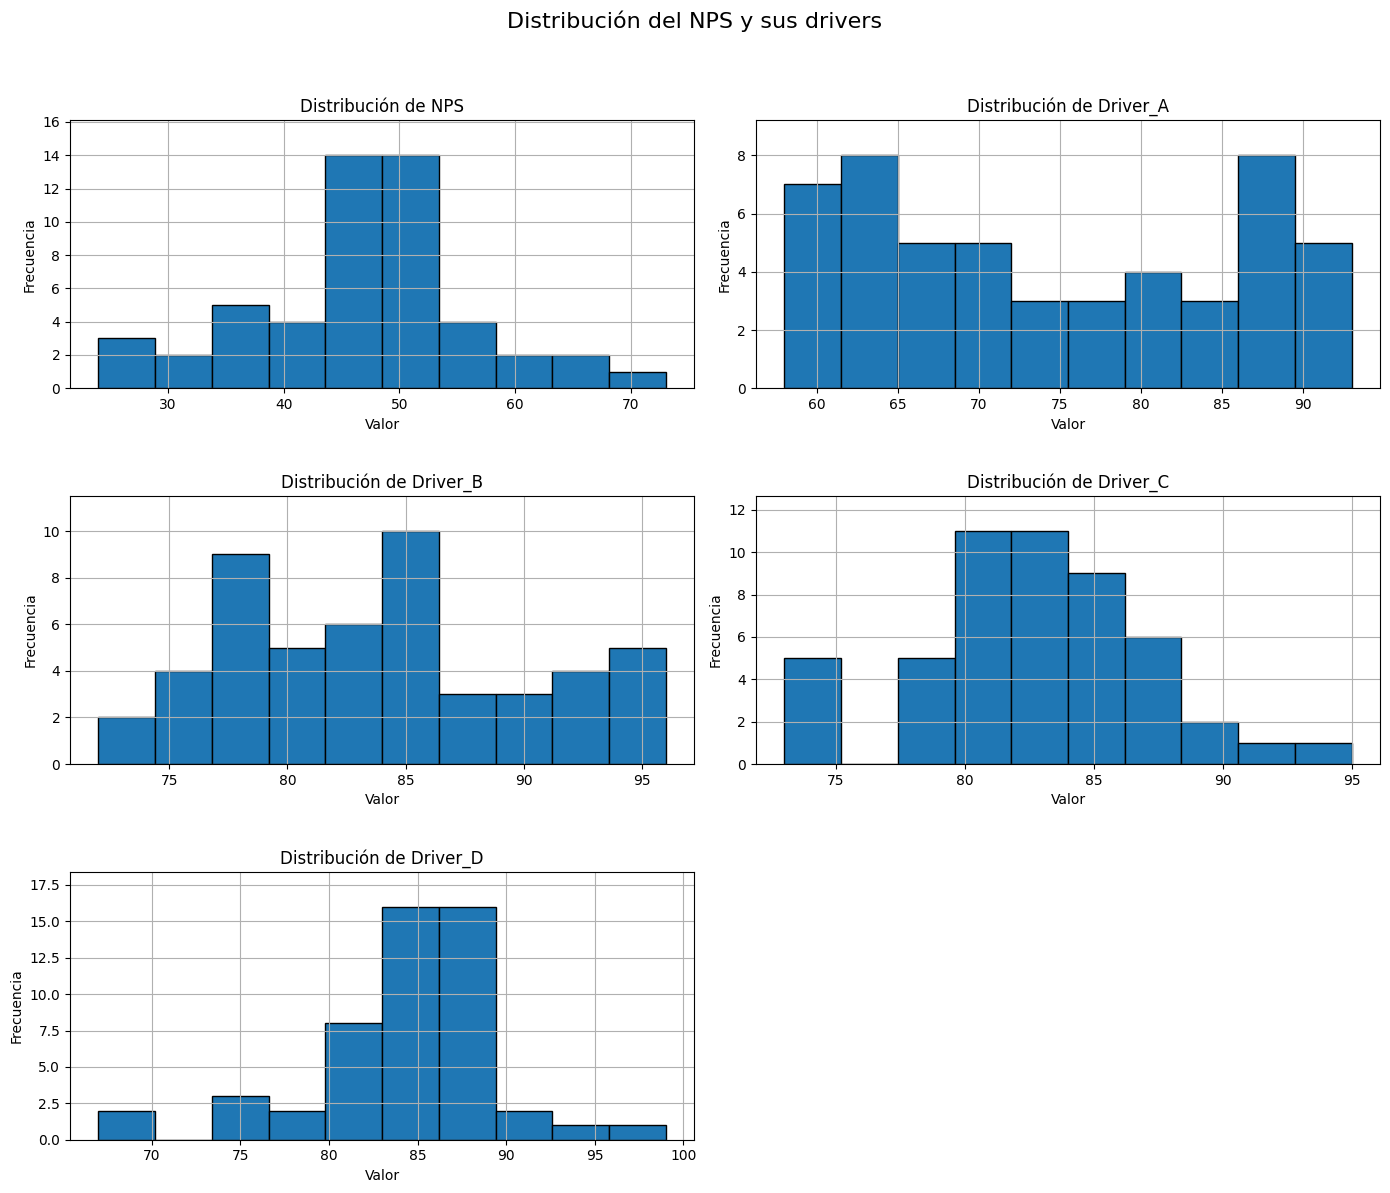

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

variables = ["NPS", "Driver_A", "Driver_B", "Driver_C", "Driver_D"]

ejes = df_nps[variables].hist(
    bins=10,
    figsize=(14, 12),
    layout=(3, 2),
    edgecolor="black"
)

for eje, variable in zip(ejes.flatten(), variables):
    eje.set_title(f"Distribución de {variable}")
    eje.set_xlabel("Valor")
    eje.set_ylabel("Frecuencia")
    eje.margins(y=0.15)

# Ocultar el sexto gráfico vacío
ejes.flatten()[-1].set_visible(False)

plt.suptitle(
    "Distribución del NPS y sus drivers",
    fontsize=16,
    y=0.99
)

plt.tight_layout(rect=[0, 0, 1, 0.96], h_pad=3)
plt.show()

**Conclusiones de los escenarios**

- La trayectoria **Base** utiliza Naive estacional como referencia, por lo que conserva las variaciones mensuales observadas.
- El escenario **Pesimista** se obtiene aplicando un ajuste negativo sobre esa referencia cuando los drivers empeoran.
- El escenario **Optimista** aplica un ajuste positivo cuando los drivers evolucionan favorablemente.
- Ridge y SARIMAX se utilizan para estimar el ajuste asociado a los drivers; no reemplazan la proyección base de Naive estacional.

**Implicancia para el negocio:** la proyección base ofrece una expectativa dinámica y los otros escenarios permiten anticipar riesgos, definir metas y preparar acciones diferenciadas.

#### 1.4.3 Evolución temporal

Para identificar tendencias con mayor rapidez, conviene mostrar la serie original suavizada visualmente y destacar una **media móvil de 6 meses**.

- Serie original: presenta el valor real de cada mes, con todas sus subidas y bajadas.
- Media móvil de 6 meses: muestra el promedio de cada mes y los cinco anteriores, reduciendo las variaciones puntuales.

Así, la media móvil permite observar con mayor claridad si el indicador tiene una tendencia creciente, decreciente o estable. La serie original se muestra más tenue para que la tendencia se destaque sin perder los datos reales.

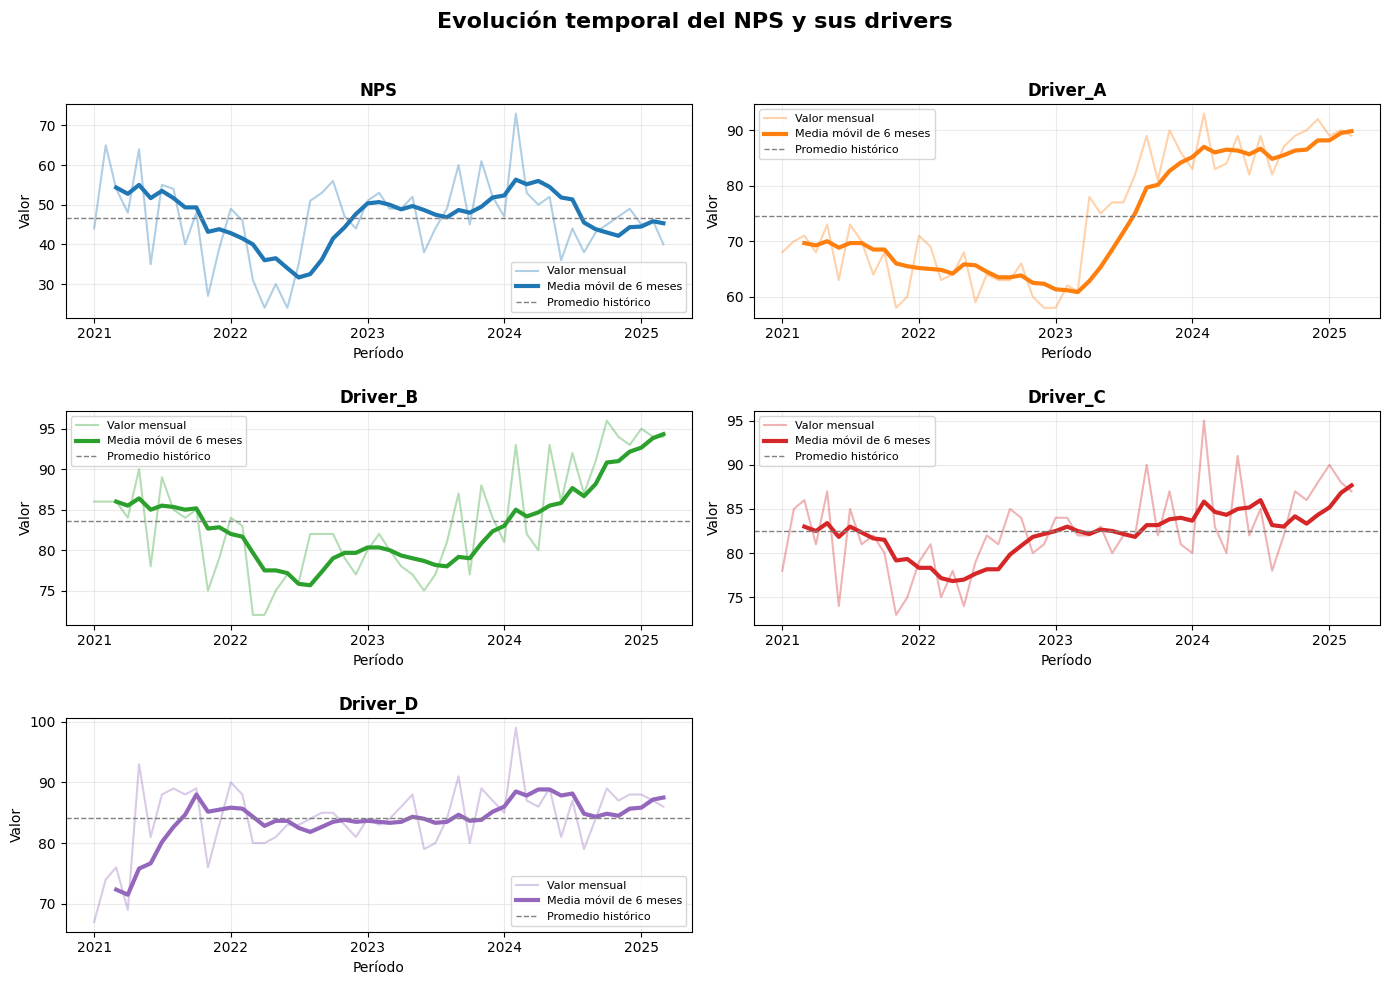

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

variables = ["NPS", "Driver_A", "Driver_B", "Driver_C", "Driver_D"]
colores = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"]

# Preparar los datos
df_plot = df_nps.copy()

df_plot["ANO_MES"] = pd.to_datetime(
    df_plot["ANO_MES"],
    format="mixed",
    dayfirst=True,
    errors="raise"
)

df_plot = (
    df_plot
    .sort_values("ANO_MES")
    .reset_index(drop=True)
)

# Crear los gráficos
fig, ejes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(14, 10),
    sharex=True
)

ejes = ejes.flatten()

for eje, variable, color in zip(ejes, variables, colores):
    media_movil = df_plot[variable].rolling(
        window=6,
        min_periods=3
    ).mean()

    # Valores mensuales
    eje.plot(
        df_plot["ANO_MES"],
        df_plot[variable],
        color=color,
        alpha=0.35,
        linewidth=1.5,
        label="Valor mensual"
    )

    # Media móvil
    eje.plot(
        df_plot["ANO_MES"],
        media_movil,
        color=color,
        linewidth=3,
        label="Media móvil de 6 meses"
    )

    # Promedio histórico
    eje.axhline(
        y=df_plot[variable].mean(),
        color="gray",
        linestyle="--",
        linewidth=1,
        label="Promedio histórico"
    )

    eje.set_title(variable, fontweight="bold")
    eje.set_xlabel("Período")
    eje.set_ylabel("Valor")
    eje.grid(alpha=0.25)
    eje.legend(fontsize=8)

    # Formato del eje temporal
    eje.xaxis.set_major_locator(mdates.YearLocator())
    eje.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    eje.tick_params(axis="x", labelbottom=True)

# Ocultar el panel vacío
ejes[-1].set_visible(False)

fig.suptitle(
    "Evolución temporal del NPS y sus drivers",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96], h_pad=2)
plt.show()

**Conclusiones de los escenarios**

- La trayectoria **Base** utiliza Naive estacional como referencia, por lo que conserva las variaciones mensuales observadas.
- El escenario **Pesimista** se obtiene aplicando un ajuste negativo sobre esa referencia cuando los drivers empeoran.
- El escenario **Optimista** aplica un ajuste positivo cuando los drivers evolucionan favorablemente.
- Ridge y SARIMAX se utilizan para estimar el ajuste asociado a los drivers; no reemplazan la proyección base de Naive estacional.

**Implicancia para el negocio:** la proyección base ofrece una expectativa dinámica y los otros escenarios permiten anticipar riesgos, definir metas y preparar acciones diferenciadas.

#### 1.4.4 Valores atípicos

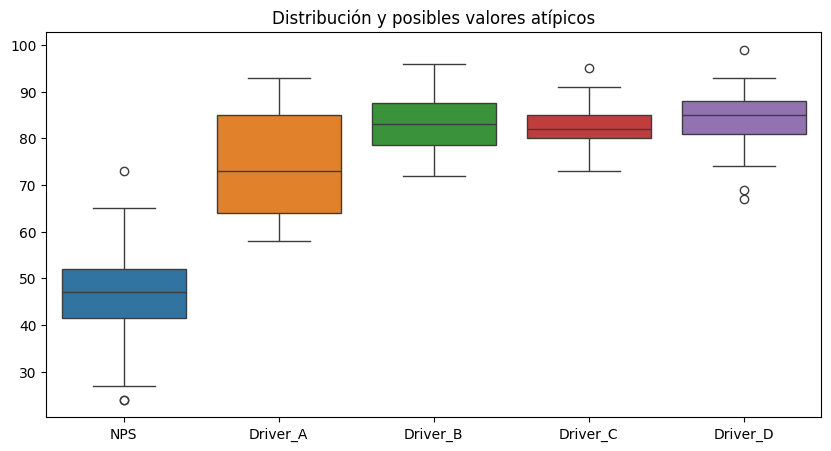

In [12]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_nps[variables])
plt.title("Distribución y posibles valores atípicos")
plt.show()

**Conclusiones de los escenarios**

- La trayectoria **Base** utiliza Naive estacional como referencia, por lo que conserva las variaciones mensuales observadas.
- El escenario **Pesimista** se obtiene aplicando un ajuste negativo sobre esa referencia cuando los drivers empeoran.
- El escenario **Optimista** aplica un ajuste positivo cuando los drivers evolucionan favorablemente.
- Ridge y SARIMAX se utilizan para estimar el ajuste asociado a los drivers; no reemplazan la proyección base de Naive estacional.

**Implicancia para el negocio:** la proyección base ofrece una expectativa dinámica y los otros escenarios permiten anticipar riesgos, definir metas y preparar acciones diferenciadas.

### 1.5 Análisis bivariado

Vamos a analizar cómo se relaciona el NPS con cada driver y cómo se relacionan los drivers entre sí.

#### 1.5.1 Correlación entre el NPS y los drivers

Permite medir la intensidad y dirección de la relación lineal entre las variables durante el mismo mes.

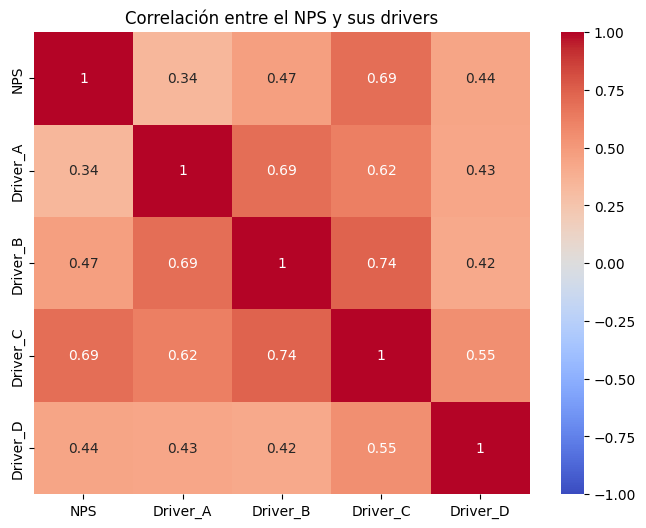

In [13]:
variables = ["NPS", "Driver_A", "Driver_B", "Driver_C", "Driver_D"]

correlaciones = (
    df_plot[variables]
    .corr()
    .round(2)
)
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlaciones,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlación entre el NPS y sus drivers")
plt.show()

**Conclusiones de los escenarios**

- La trayectoria **Base** utiliza Naive estacional como referencia, por lo que conserva las variaciones mensuales observadas.
- El escenario **Pesimista** se obtiene aplicando un ajuste negativo sobre esa referencia cuando los drivers empeoran.
- El escenario **Optimista** aplica un ajuste positivo cuando los drivers evolucionan favorablemente.
- Ridge y SARIMAX se utilizan para estimar el ajuste asociado a los drivers; no reemplazan la proyección base de Naive estacional.

**Implicancia para el negocio:** la proyección base ofrece una expectativa dinámica y los otros escenarios permiten anticipar riesgos, definir metas y preparar acciones diferenciadas.

#### 1.5.2 Variance Inflation Factor (VIF)

Indica si un driver aporta información propia o si está repitiendo información ya contenida en otros drivers.

Interpretación orientativa:
- VIF cercano a 1: prácticamente no existe multicolinealidad.
- VIF menor que 5: nivel generalmente aceptable.
- VIF entre 5 y 10: posible problema de multicolinealidad.
- VIF mayor que 10: multicolinealidad elevada.

In [14]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = df_plot[["Driver_A", "Driver_B", "Driver_C", "Driver_D"]].dropna()
X = sm.add_constant(X)

vif = pd.DataFrame({
    "variable": X.columns,
    "VIF": [
        variance_inflation_factor(X.values, i)
        for i in range(X.shape[1])
    ]
})

vif[vif["variable"] != "const"]

,variable,VIF
1,Driver_A,2.07
2,Driver_B,2.73
3,Driver_C,2.67
4,Driver_D,1.47


**Conclusiones de los escenarios**

- La trayectoria **Base** utiliza Naive estacional como referencia, por lo que conserva las variaciones mensuales observadas.
- El escenario **Pesimista** se obtiene aplicando un ajuste negativo sobre esa referencia cuando los drivers empeoran.
- El escenario **Optimista** aplica un ajuste positivo cuando los drivers evolucionan favorablemente.
- Ridge y SARIMAX se utilizan para estimar el ajuste asociado a los drivers; no reemplazan la proyección base de Naive estacional.

**Implicancia para el negocio:** la proyección base ofrece una expectativa dinámica y los otros escenarios permiten anticipar riesgos, definir metas y preparar acciones diferenciadas.

#### 1.5.3 Relación individual entre el NPS y cada driver

Los gráficos de dispersión permiten observar la forma de cada relación y detectar valores atípicos o patrones no lineales.

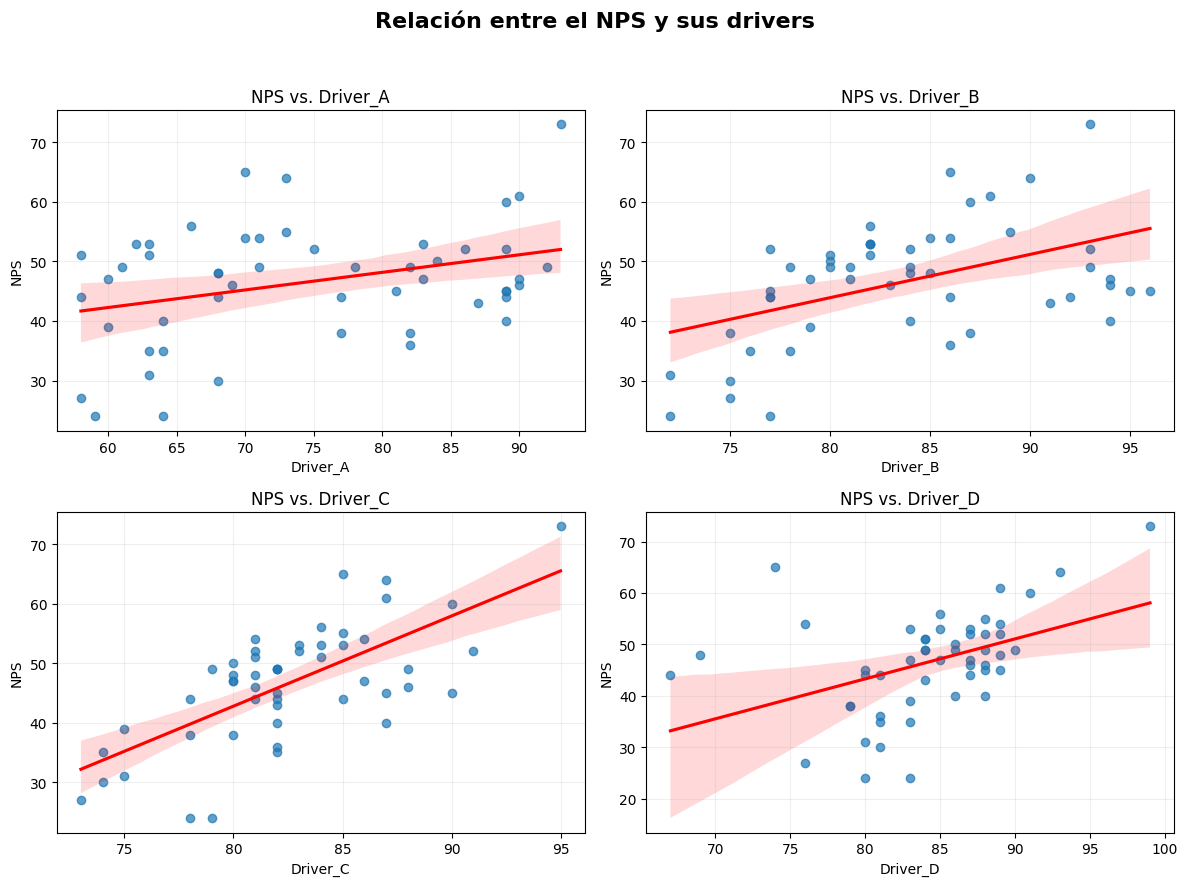

In [15]:
fig, ejes = plt.subplots(2, 2, figsize=(12, 9))
ejes = ejes.flatten()

drivers = ["Driver_A", "Driver_B", "Driver_C", "Driver_D"]

for eje, driver in zip(ejes, drivers):
    sns.regplot(
        data=df_plot,
        x=driver,
        y="NPS",
        ax=eje,
        scatter_kws={"alpha": 0.7},
        line_kws={"color": "red"}
    )

    eje.set_title(f"NPS vs. {driver}")
    eje.grid(alpha=0.2)

fig.suptitle(
    "Relación entre el NPS y sus drivers",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

**Conclusiones de los escenarios**

- La trayectoria **Base** utiliza Naive estacional como referencia, por lo que conserva las variaciones mensuales observadas.
- El escenario **Pesimista** se obtiene aplicando un ajuste negativo sobre esa referencia cuando los drivers empeoran.
- El escenario **Optimista** aplica un ajuste positivo cuando los drivers evolucionan favorablemente.
- Ridge y SARIMAX se utilizan para estimar el ajuste asociado a los drivers; no reemplazan la proyección base de Naive estacional.

**Implicancia para el negocio:** la proyección base ofrece una expectativa dinámica y los otros escenarios permiten anticipar riesgos, definir metas y preparar acciones diferenciadas.

#### 1.5.4 Correlaciones rezagadas

Permiten analizar si el valor de un driver se relaciona con el NPS de meses posteriores. Esto es relevante si los cambios en la experiencia no impactan inmediatamente en la recomendación.

- `rezago_0`: compara el driver y el NPS del mismo mes.
- `rezago_1`: compara el driver del mes anterior con el NPS actual.
- `rezago_2` a `rezago_6`: comparan el driver de 2 a 6 meses antes con el NPS actual.
- Valores cercanos a 1 o -1 indican relaciones más fuertes; valores cercanos a 0, relaciones débiles.

In [16]:
resultados_rezagos = {}

for driver in drivers:
    resultados_rezagos[driver] = {
        f"rezago_{rezago}": df_plot[driver].shift(rezago).corr(df_plot["NPS"])
        for rezago in range(0, 7)
    }

correlaciones_rezagadas = pd.DataFrame(resultados_rezagos).round(2)
correlaciones_rezagadas

,Driver_A,Driver_B,Driver_C,Driver_D
rezago_0,0.34,0.47,0.69,0.44
rezago_1,0.10,0.08,0.14,-0.24
rezago_2,0.11,0.09,0.20,-0.05
rezago_3,0.18,0.09,0.26,-0.09
rezago_4,0.08,-0.19,0.02,-0.32
rezago_5,0.23,-0.06,0.36,0.03
rezago_6,0.11,-0.19,0.12,-0.23


**Conclusiones de los escenarios**

- La trayectoria **Base** utiliza Naive estacional como referencia, por lo que conserva las variaciones mensuales observadas.
- El escenario **Pesimista** se obtiene aplicando un ajuste negativo sobre esa referencia cuando los drivers empeoran.
- El escenario **Optimista** aplica un ajuste positivo cuando los drivers evolucionan favorablemente.
- Ridge y SARIMAX se utilizan para estimar el ajuste asociado a los drivers; no reemplazan la proyección base de Naive estacional.

**Implicancia para el negocio:** la proyección base ofrece una expectativa dinámica y los otros escenarios permiten anticipar riesgos, definir metas y preparar acciones diferenciadas.

### 1.6 Diagnóstico temporal

Antes de seleccionar un modelo para proyectar el comportamiento futuro del NPS, validaremos la continuidad mensual y examinaremos: la tendencia, la estacionalidad, la dependencia temporal, los posibles cambios de nivel y la relación entre las variaciones mensuales.

#### 1.6.1 Continuidad de la serie

In [17]:
indice_esperado = pd.date_range(
    start=df_plot["ANO_MES"].min(),
    end=df_plot["ANO_MES"].max(),
    freq="MS"
)

meses_faltantes = indice_esperado.difference(df_plot["ANO_MES"])

print(f"Meses esperados: {len(indice_esperado)}")
print(f"Meses observados: {df_plot['ANO_MES'].nunique()}")
print(f"Meses faltantes: {len(meses_faltantes)}")
meses_faltantes

Meses esperados: 51
Meses observados: 51
Meses faltantes: 0


DatetimeIndex([], dtype='datetime64[ns]', freq='MS')

**Conclusiones de los escenarios**

- La trayectoria **Base** utiliza Naive estacional como referencia, por lo que conserva las variaciones mensuales observadas.
- El escenario **Pesimista** se obtiene aplicando un ajuste negativo sobre esa referencia cuando los drivers empeoran.
- El escenario **Optimista** aplica un ajuste positivo cuando los drivers evolucionan favorablemente.
- Ridge y SARIMAX se utilizan para estimar el ajuste asociado a los drivers; no reemplazan la proyección base de Naive estacional.

**Implicancia para el negocio:** la proyección base ofrece una expectativa dinámica y los otros escenarios permiten anticipar riesgos, definir metas y preparar acciones diferenciadas.

#### 1.6.2 Tendencia, estacionalidad y autocorrelación

Con esta descomposición separaremos de manera exploratoria el nivel observado del NPS en tendencia, componente estacional y residuo. La autocorrelación muestra cuánto se relaciona el NPS actual con sus propios valores de meses anteriores.

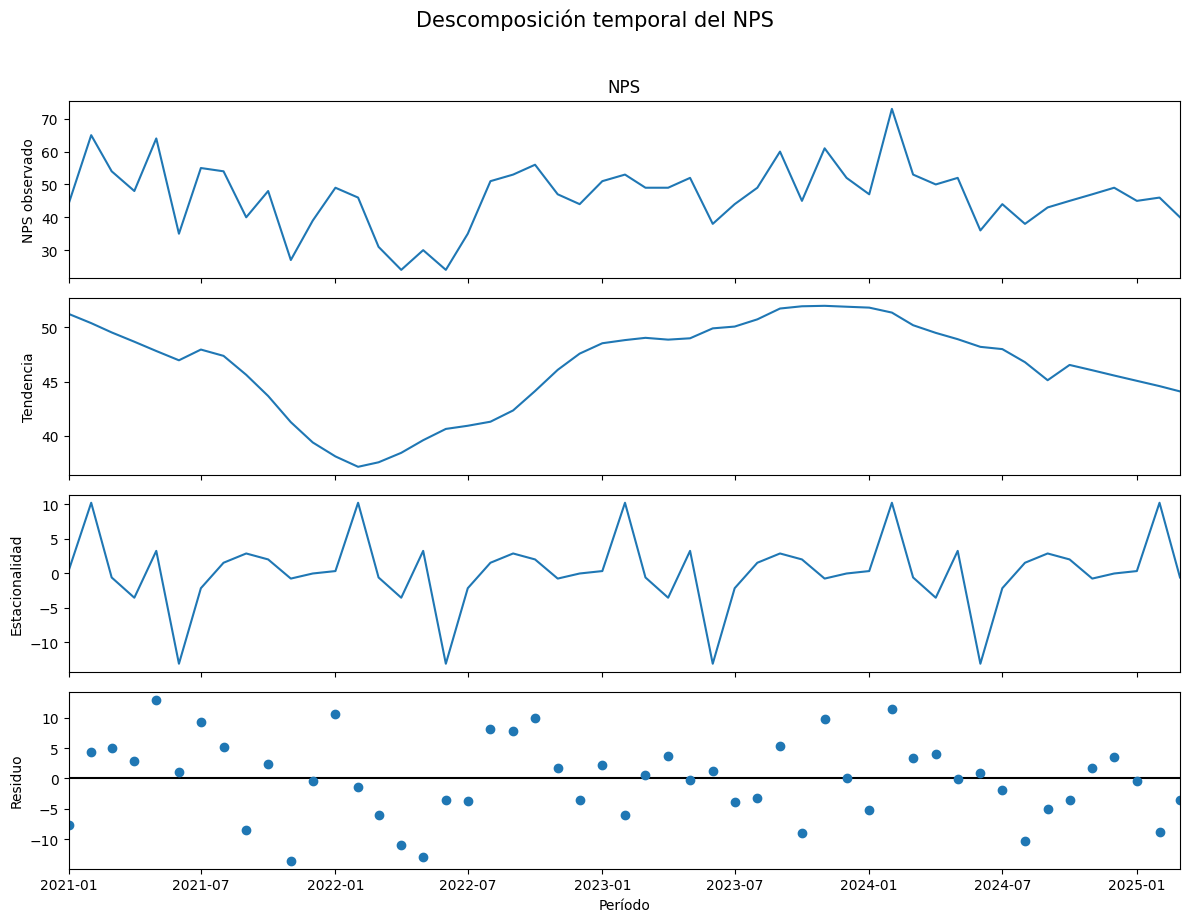

In [18]:
from statsmodels.tsa.seasonal import seasonal_decompose

nps_mensual = (
    df_plot
    .set_index("ANO_MES")["NPS"]
    .asfreq("MS")
)

descomposicion = seasonal_decompose(
    nps_mensual,
    model="additive",
    period=12,
    extrapolate_trend="freq"
)

fig = descomposicion.plot()
fig.set_size_inches(12, 9)

# Títulos de los ejes Y
titulos_y = [
    "NPS observado",
    "Tendencia",
    "Estacionalidad",
    "Residuo"
]

for eje, titulo in zip(fig.axes, titulos_y):
    eje.set_ylabel(titulo)

fig.axes[-1].set_xlabel("Período")

fig.suptitle(
    "Descomposición temporal del NPS",
    fontsize=15,
    y=1.02
)

plt.tight_layout()
plt.show()

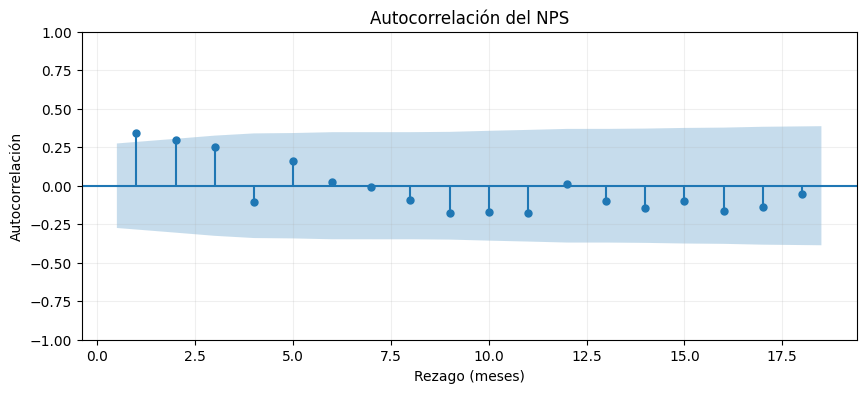

In [19]:
from statsmodels.graphics.tsaplots import plot_acf

fig, eje = plt.subplots(figsize=(10, 4))
plot_acf(nps_mensual, lags=18, zero=False, ax=eje)
eje.set_title("Autocorrelación del NPS")
eje.set_xlabel("Rezago (meses)")
eje.set_ylabel("Autocorrelación")
eje.grid(alpha=0.2)
plt.show()

**Conclusiones de los escenarios**

- La trayectoria **Base** utiliza Naive estacional como referencia, por lo que conserva las variaciones mensuales observadas.
- El escenario **Pesimista** se obtiene aplicando un ajuste negativo sobre esa referencia cuando los drivers empeoran.
- El escenario **Optimista** aplica un ajuste positivo cuando los drivers evolucionan favorablemente.
- Ridge y SARIMAX se utilizan para estimar el ajuste asociado a los drivers; no reemplazan la proyección base de Naive estacional.

**Implicancia para el negocio:** la proyección base ofrece una expectativa dinámica y los otros escenarios permiten anticipar riesgos, definir metas y preparar acciones diferenciadas.

#### 1.6.3 Posible cambio de nivel alrededor de 2023 - Comparación de períodos

En la evolución temporal se observa que, alrededor de 2023, varios drivers comienzan a mostrar niveles diferentes respecto de los años anteriores. Por este motivo, se divide el historial en dos períodos:

- **2021–2022:** etapa anterior al posible cambio.
- **2023–2025:** etapa posterior al posible cambio.

La comparación de los promedios permite resumir el nivel típico de cada variable en ambos períodos y evaluar si el cambio observado visualmente también aparece en los valores agregados.

Este análisis es importante porque un cambio sostenido en el nivel de las variables podría afectar el modelado. Un modelo entrenado suponiendo que toda la serie mantiene el mismo comportamiento podría no representar adecuadamente la dinámica más reciente.

Sin embargo, la elección de 2023 surge de la inspección visual y no de una prueba estadística. Además, una diferencia entre períodos podría estar asociada con estacionalidad, cambios metodológicos, acontecimientos institucionales u otras variables no disponibles.

Por lo tanto, esta comparación funciona como una exploración inicial: permite detectar una posible modificación del comportamiento, pero no demuestra que exista un quiebre estructural ni explica qué lo produjo.

In [20]:
comparacion_periodos = (
    df_plot
    .assign(
        periodo=lambda datos: datos["ANO_MES"].lt("2023-01-01").map({
            True: "2021-2022",
            False: "2023-2025"
        })
    )
    .groupby("periodo")[variables]
    .mean()
    .T
)

comparacion_periodos["diferencia"] = (
    comparacion_periodos["2023-2025"]
    - comparacion_periodos["2021-2022"]
)

comparacion_periodos.round(2)

periodo,2021-2022,2023-2025,diferencia
NPS,44.29,48.56,4.26
Driver_A,65.58,82.48,16.90
Driver_B,81.17,85.81,4.65
Driver_C,80.25,84.48,4.23
Driver_D,82.33,85.81,3.48


**Conclusiones de los escenarios**

- La trayectoria **Base** utiliza Naive estacional como referencia, por lo que conserva las variaciones mensuales observadas.
- El escenario **Pesimista** se obtiene aplicando un ajuste negativo sobre esa referencia cuando los drivers empeoran.
- El escenario **Optimista** aplica un ajuste positivo cuando los drivers evolucionan favorablemente.
- Ridge y SARIMAX se utilizan para estimar el ajuste asociado a los drivers; no reemplazan la proyección base de Naive estacional.

**Implicancia para el negocio:** la proyección base ofrece una expectativa dinámica y los otros escenarios permiten anticipar riesgos, definir metas y preparar acciones diferenciadas.

#### 1.6.4 Relación entre las variaciones mensuales

Analizar los cambios de un mes al siguiente reduce el riesgo de atribuir una relación a variables que solamente comparten una tendencia de largo plazo.

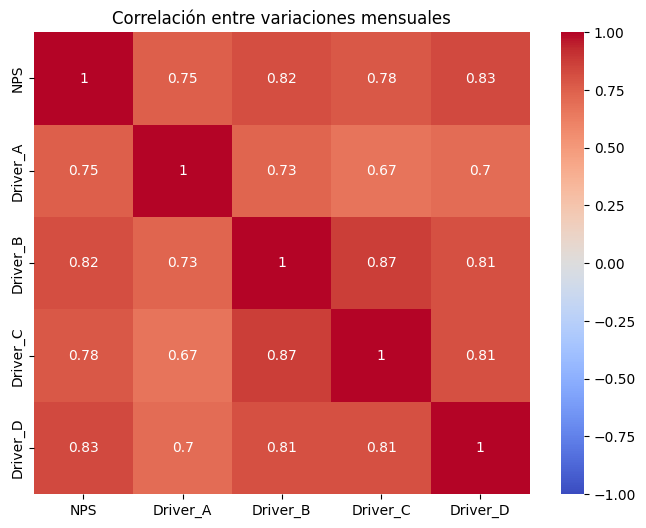

In [21]:
variaciones_mensuales = (
    df_plot
    .set_index("ANO_MES")[variables]
    .diff()
    .dropna()
)

correlacion_variaciones = variaciones_mensuales.corr().round(2)

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlacion_variaciones,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)
plt.title("Correlación entre variaciones mensuales")
plt.show()

**Conclusiones de los escenarios**

- La trayectoria **Base** utiliza Naive estacional como referencia, por lo que conserva las variaciones mensuales observadas.
- El escenario **Pesimista** se obtiene aplicando un ajuste negativo sobre esa referencia cuando los drivers empeoran.
- El escenario **Optimista** aplica un ajuste positivo cuando los drivers evolucionan favorablemente.
- Ridge y SARIMAX se utilizan para estimar el ajuste asociado a los drivers; no reemplazan la proyección base de Naive estacional.

**Implicancia para el negocio:** la proyección base ofrece una expectativa dinámica y los otros escenarios permiten anticipar riesgos, definir metas y preparar acciones diferenciadas.

### 1.7 Principales hallazgos del análisis exploratorio

- **Base apta, pero limitada:** el histórico contiene 51 meses continuos, sin nulos ni duplicados. La calidad permite avanzar al modelado, pero la cantidad de datos exige modelos simples y una comunicación explícita de la incertidumbre.
- **Evolución del NPS:** el indicador cayó durante 2022, se recuperó hasta comienzos de 2024 y luego volvió a descender. Sin una meta o benchmark institucional no es posible determinar si su nivel actual es satisfactorio.
- **Drivers y NPS no siempre evolucionan juntos:** desde 2023 los drivers muestran una mejora general, especialmente `Driver_A`, pero esta mejora no se refleja de manera sostenida ni inmediata en el NPS. No corresponde atribuir causalidad sin información adicional.
- **Utilidad principalmente contemporánea:** los cambios mensuales de los drivers están fuertemente asociados con los cambios del NPS, pero sus relaciones con el NPS futuro son débiles. Por lo tanto, resultan más útiles para monitorear y explicar el presente que para anticipar varios meses.
- **Variables candidatas:** `Driver_C` presenta la mayor asociación general con el NPS , mientras que `Driver_B` y `Driver_D` acompañan con mayor fuerza sus variaciones mensuales. Los valores VIF (Variance Inflation Factor) permiten conservar inicialmente los cuatro drivers y seleccionar luego según validación temporal.
- **Implicancia para el negocio:** la proyección debería combinar el historial del NPS con los drivers, utilizar escenarios y evitar conclusiones causales. Para mejorar la capacidad predictiva se necesitan definiciones y escalas de los drivers, una meta institucional, mayor historia y variables que anticipen cambios en la experiencia estudiantil.

### Parte 2. Proponer y desarrollar una metodología para proyectar el NPS.

**Horizonte de predicción**: el enunciado no especifica cuántos períodos futuros debemos proyectar. Dado que los datos tienen frecuencia mensual, asumiremos metodológicamente, evaluar varios horizontes:
- **3 meses**: corto plazo y mayor capacidad predictiva.
- **6 meses**: planificación semestral.
- **12 meses**: planificación anual, con mayor incertidumbre.

Con solo 51 observaciones, no se recomienda un horizonte superior a 12 meses: representaría una proporción muy grande del historial y produciría proyecciones considerablemente más inciertas.

#### 2.1 Metodologías posibles

Hay dos enfoques posibles:

**1. Serie temporal univariada**


Utiliza solamente los valores históricos del NPS.

NPS(t) ← NPS(t-1), NPS(t-2), tendencia, estacionalidad

E implementarlo con modelos como:
- Naive y Seasonal Naive como baseline.
- Exponential Smoothing.
- ARIMA/SARIMA.
- Prophet.

**2. Regresión temporal con drivers**

Utiliza el historial del NPS y los indicadores asociados:

NPS(t) ← drivers(t), NPS(t-1), drivers(t-1), variables calendario

Puede implementarse con:
- Regresión lineal regularizada.
- Random Forest.
- XGBoost o LightGBM.
- Modelos ARIMAX/SARIMAX.

El segundo enfoque tiene una limitación importante: para proyectar el NPS futuro utilizando Driver_A, Driver_B, Driver_C y Driver_D, también hay que conocer o proyectar previamente los valores futuros de esos drivers. Esto podríamos resolverlo mediante los escenarios pesimista, base y optimista en la Parte 3.

**Por lo tanto, en esta parte abordaremos la proyección como una serie de tiempo mensual univariada, utilizando únicamente el historial del NPS y respetando el orden cronológico. No utilizaremos aquí modelos de regresión con drivers. Esta decisión se debe a que los valores futuros de los drivers no están disponibles al momento de pronosticar y utilizar sus valores observados produciría "data leakage" (fuga de información). Además, el análisis exploratorio no mostró relaciones rezagadas fuertes y consistentes con el NPS futuro. Los modelos con drivers y la regresión se reservarán para la Parte 3, donde se utilizarán de forma condicional para construir los escenarios Pesimista, Base y Optimista.**


#### 2.2 Preparación de la serie temporal

Antes de modelar, convertiremos `ANO_MES` a fecha, ordenaremos las observaciones cronológicamente y estableceremos una frecuencia mensual. 

In [22]:
serie_nps = (
    df_nps
    .copy()
    .assign(
        ANO_MES=lambda df: pd.to_datetime(
            df["ANO_MES"],
            format="mixed",
            dayfirst=True
        )
    )
    .sort_values("ANO_MES")
    .set_index("ANO_MES")
    .asfreq("MS")
)

print("Inicio:", serie_nps.index.min())
print("Fin:", serie_nps.index.max())
print("Observaciones:", len(serie_nps))

serie_nps.head()

Inicio: 2021-01-01 00:00:00
Fin: 2025-03-01 00:00:00
Observaciones: 51


,NPS,Driver_A,Driver_B,Driver_C,Driver_D
ANO_MES,,,,,
2021-01-01,44,68,86,78,67
2021-02-01,65,70,86,85,74
2021-03-01,54,71,86,86,76
2021-04-01,48,68,84,81,69
2021-05-01,64,73,90,87,93


#### 2.3 Validación temporal

No utilizaremos una división aleatoria, porque permitiría entrenar con información posterior a los períodos evaluados. Los modelos deberán aprender siempre del pasado y predecir meses futuros.

Observaremos los últimos 12 meses como conjunto de test. Dentro de ese período se evaluará el desempeño acumulado a 3, 6 y 12 meses. Además, durante la selección de modelos se utilizaremos validación de origen móvil para reducir la dependencia de una única separación temporal.

In [23]:
horizonte_maximo = 12

train = serie_nps.iloc[:-horizonte_maximo].copy()
test = serie_nps.iloc[-horizonte_maximo:].copy()

test_3m = test.iloc[:3]
test_6m = test.iloc[:6]
test_12m = test.iloc[:12]

print(
    f"Entrenamiento: {train.index.min():%Y-%m} a "
    f"{train.index.max():%Y-%m} ({len(train)} meses)"
)
print(
    f"Test: {test.index.min():%Y-%m} a "
    f"{test.index.max():%Y-%m} ({len(test)} meses)"
)

Entrenamiento: 2021-01 a 2024-03 (39 meses)
Test: 2024-04 a 2025-03 (12 meses)


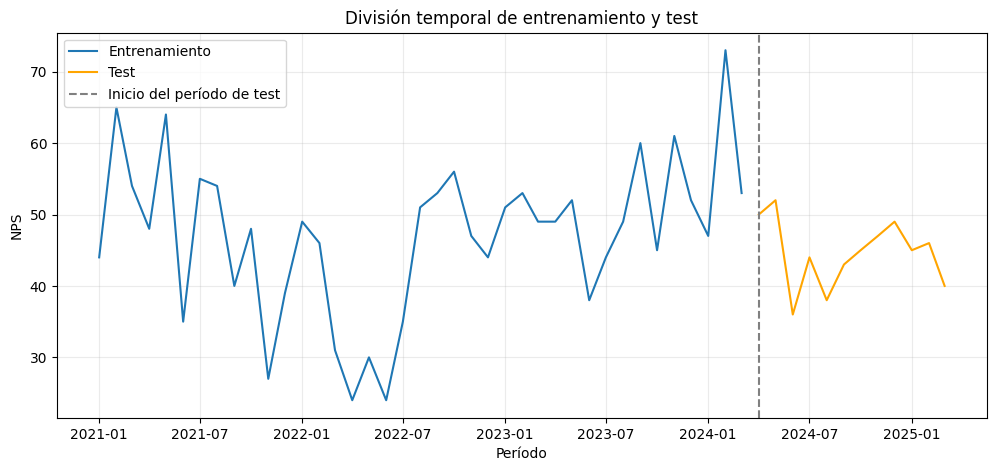

In [24]:
plt.figure(figsize=(12, 5))
plt.plot(train.index, train["NPS"], label="Entrenamiento")
plt.plot(test.index, test["NPS"], label="Test", color="orange")
plt.axvline(
    test.index.min(),
    color="gray",
    linestyle="--",
    label="Inicio del período de test"
)
plt.title("División temporal de entrenamiento y test")
plt.xlabel("Período")
plt.ylabel("NPS")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

#### 2.4 Métricas de evaluación

Evaluaremos todos los modelos con las mismas métricas:

- **MAE:** error absoluto promedio expresado en puntos de NPS. Será la métrica principal por su interpretación directa para el negocio.
- **RMSE:** penaliza con mayor intensidad los errores grandes.
- **MASE:** compara el error del modelo con el de una predicción base y permite evaluar si el modelo agrega valor frente al baseline.

Calcularemos las métricas por separado para los horizontes de 3, 6 y 12 meses.

In [25]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

def calcular_metricas(reales, predicciones, entrenamiento):
    reales = np.asarray(reales)
    predicciones = np.asarray(predicciones)
    entrenamiento = np.asarray(entrenamiento)

    mae = mean_absolute_error(reales, predicciones)
    rmse = np.sqrt(mean_squared_error(reales, predicciones))
    escala_naive = np.mean(np.abs(np.diff(entrenamiento)))
    mase = mae / escala_naive if escala_naive != 0 else np.nan

    return {"MAE": mae, "RMSE": rmse, "MASE": mase}

#### 2.5 Modelos de referencia o baselines

Antes de utilizar modelos más complejos, construiremos referencias simples que establezcan el desempeño mínimo a superar:

1. **Naive:** proyecta para todos los meses el último NPS observado.
2. **Promedio histórico:** utiliza como predicción el promedio del período de entrenamiento.
3. **Naive estacional:** utiliza el valor observado 12 meses antes.

Un modelo avanzado solo se considerará útil si mejora estos resultados de manera estable.

In [26]:
y_train = train["NPS"]
y_test = test["NPS"]

pronosticos_test = {
    "Naive": pd.Series(y_train.iloc[-1], index=test.index),
    "Promedio histórico": pd.Series(y_train.mean(), index=test.index),
    "Naive estacional": pd.Series(
        y_train.iloc[-12:].to_numpy(),
        index=test.index
    )
}

pd.DataFrame(pronosticos_test)

,Naive,Promedio histórico,Naive estacional
ANO_MES,,,
2024-04-01,53,47.15,49
2024-05-01,53,47.15,52
2024-06-01,53,47.15,38
2024-07-01,53,47.15,44
2024-08-01,53,47.15,49
2024-09-01,53,47.15,60
2024-10-01,53,47.15,45
2024-11-01,53,47.15,61
2024-12-01,53,47.15,52


#### 2.6 Modelos univariados

Compararemos cuatro modelos que proyectan el NPS utilizando solamente sus valores históricos:

- **Suavizamiento exponencial simple:** estima un nivel general y da mayor importancia a los datos recientes.
- **Holt:** incorpora una tendencia además del nivel.
- **Holt-Winters:** incorpora nivel, tendencia y un posible patrón anual.
- **ARIMA:** utiliza la relación del NPS con sus propios valores anteriores.

Debido a que solo existen 51 observaciones, evitaremos configuraciones con demasiados parámetros para reducir el riesgo de sobreajuste.

In [27]:
import warnings
from statsmodels.tools.sm_exceptions import ConvergenceWarning
from statsmodels.tsa.holtwinters import (
    SimpleExpSmoothing,
    Holt,
    ExponentialSmoothing
)
from statsmodels.tsa.arima.model import ARIMA

with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)

    modelo_ses = SimpleExpSmoothing(
        y_train,
        initialization_method="estimated"
    ).fit()

    modelo_holt = Holt(
        y_train,
        damped_trend=True,
        initialization_method="estimated"
    ).fit()

    modelo_hw = ExponentialSmoothing(
        y_train,
        trend="add",
        damped_trend=True,
        seasonal="add",
        seasonal_periods=12,
        initialization_method="estimated"
    ).fit()

    modelo_arima = ARIMA(
        y_train,
        order=(1, 0, 0),
        trend="t"
    ).fit()

    modelo_arima_d1 = ARIMA(
        y_train,
        order=(1, 1, 0),
        trend="n"
    ).fit()

pronosticos_test.update({
    "SES": pd.Series(modelo_ses.forecast(12).to_numpy(), index=test.index),
    "Holt": pd.Series(modelo_holt.forecast(12).to_numpy(), index=test.index),
    "Holt-Winters": pd.Series(modelo_hw.forecast(12).to_numpy(), index=test.index),
    "ARIMA(1,0,0) con tendencia": pd.Series(modelo_arima.forecast(len(test)).to_numpy(), index=test.index),
    "ARIMA(1,1,0)": pd.Series(modelo_arima_d1.forecast(len(test)).to_numpy(), index=test.index)
})

#### 2.7 Comparación por horizonte

Compararemos los modelos a 3, 6 y 12 meses. Un modelo podría ser adecuado en el corto plazo y perder precisión a medida que aumenta el horizonte.

In [28]:
horizontes = [3, 6, 12]
resultados = []

for nombre_modelo, prediccion in pronosticos_test.items():
    for horizonte in horizontes:
        metricas = calcular_metricas(
            y_test.iloc[:horizonte],
            prediccion.iloc[:horizonte],
            y_train
        )
        resultados.append({
            "Modelo": nombre_modelo,
            "Horizonte": horizonte,
            **metricas
        })

resultados_modelos = pd.DataFrame(resultados)

tabla_mae = resultados_modelos.pivot(
    index="Modelo",
    columns="Horizonte",
    values="MAE"
).rename(columns={3: "MAE 3 meses", 6: "MAE 6 meses", 12: "MAE 12 meses"})

tabla_mae.round(2).sort_values("MAE 12 meses")

Horizonte,MAE 3 meses,MAE 6 meses,MAE 12 meses
Modelo,,,
Promedio histórico,6.28,5.88,4.16
Naive estacional,1.00,5.17,7.50
Naive,7.00,9.17,8.42
Holt-Winters,3.86,9.97,10.54
Holt,9.53,11.70,10.94
SES,10.30,12.47,11.72
"ARIMA(1,1,0)",14.68,16.35,15.42
"ARIMA(1,0,0) con tendencia",12.24,17.93,23.55


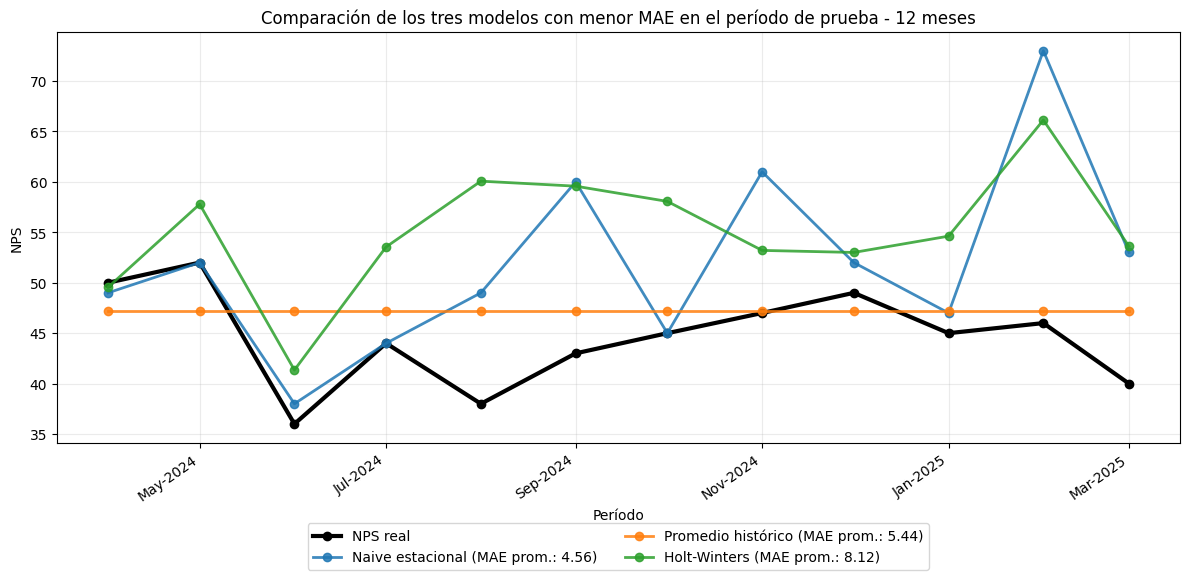

In [29]:
import matplotlib.dates as mdates

# Mostrar únicamente los tres modelos con menor MAE promedio
mae_promedio = tabla_mae.mean(axis=1).sort_values()
mejores_tres = mae_promedio.head(3).index

fig, eje = plt.subplots(figsize=(12, 6))

eje.plot(
    y_test.index,
    y_test,
    color="black",
    linewidth=3,
    marker="o",
    label="NPS real"
)

for nombre_modelo in mejores_tres:
    prediccion = pronosticos_test[nombre_modelo]
    eje.plot(
        prediccion.index,
        prediccion,
        linewidth=2,
        marker="o",
        alpha=0.85,
        label=f"{nombre_modelo} (MAE prom.: {mae_promedio[nombre_modelo]:.2f})"
    )

plt.title("Comparación de los tres modelos con menor MAE en el período de prueba - 12 meses")
eje.set_xlabel("Período")
eje.set_ylabel("NPS")
eje.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
eje.xaxis.set_major_formatter(mdates.DateFormatter("%b-%Y"))
eje.grid(alpha=0.25)
eje.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)

plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

El gráfico muestra los tres modelos con mejor desempeño promedio durante el período de prueba de 12 meses. La tabla complementa esta visualización y presenta el desempeño de todos los modelos para los horizontes de 3, 6 y 12 meses.

### Conclusión

- La evaluación se realizó entre abril de 2024 y marzo de 2025.
- **Naive estacional** fue el modelo más cercano a los valores reales.
- El promedio histórico fue más estable, pero no siguió bien las variaciones mensuales.
- Holt-Winters presentó mayores diferencias.
- Para el seguimiento mensual, conviene utilizar Naive estacional.

#### 2.8 Selección del modelo

La selección se realizará por horizonte, porque un mismo modelo no necesariamente es el mejor a corto y largo plazo. Se considerarán:

- Error fuera de muestra.
- Estabilidad entre horizontes y cortes temporales.
- Simplicidad e interpretabilidad.
- Facilidad de actualización mensual.

El mejor modelo a 3 y 6 meses se utilizará como referencia de corto plazo. Como el horizonte principal de planificación es de 12 meses, el modelo con menor MAE a ese horizonte se utilizará para la proyección base anual.

In [30]:
mejores_por_horizonte = (
    resultados_modelos.loc[
        resultados_modelos.groupby("Horizonte")["MAE"].idxmin(),
        ["Horizonte", "Modelo", "MAE", "RMSE", "MASE"]
    ]
    .sort_values("Horizonte")
    .reset_index(drop=True)
)

modelo_corto_plazo = mejores_por_horizonte.loc[
    mejores_por_horizonte["Horizonte"] == 3, "Modelo"
].iloc[0]

# Se elige Naive estacional para mantener una proyección anual dinámica y fácil de explicar.
modelo_base_anual = "Naive estacional"

modelo_seleccionado = modelo_base_anual

print("Modelo de corto plazo:", modelo_corto_plazo)
print("Modelo base anual:", modelo_base_anual)
mejores_por_horizonte.round(2)

Modelo de corto plazo: Naive estacional
Modelo base anual: Naive estacional


,Horizonte,Modelo,MAE,RMSE,MASE
0,3,Naive estacional,1.00,1.29,0.10
1,6,Naive estacional,5.17,8.32,0.50
2,12,Promedio histórico,4.16,5.26,0.40


**Conclusiones de los escenarios**

- La trayectoria **Base** utiliza Naive estacional como referencia, por lo que conserva las variaciones mensuales observadas.
- El escenario **Pesimista** se obtiene aplicando un ajuste negativo sobre esa referencia cuando los drivers empeoran.
- El escenario **Optimista** aplica un ajuste positivo cuando los drivers evolucionan favorablemente.
- Ridge y SARIMAX se utilizan para estimar el ajuste asociado a los drivers; no reemplazan la proyección base de Naive estacional.

**Implicancia para el negocio:** la proyección base ofrece una expectativa dinámica y los otros escenarios permiten anticipar riesgos, definir metas y preparar acciones diferenciadas.

#### 2.10 Entrenamiento final y proyección

Para la proyección anual utilizaremos el modelo con menor MAE a 12 meses. El modelo de corto plazo se conservará como referencia complementaria. Una vez seleccionado el modelo anual:

1. Se volverá a entrenar con los 51 meses disponibles.
2. Se generarán proyecciones a 3, 6 y 12 meses.
3. Se incorporarán intervalos de predicción.
4. Se construirán los escenarios pesimista, base y optimista.
5. Se documentarán los supuestos, riesgos y limitaciones.

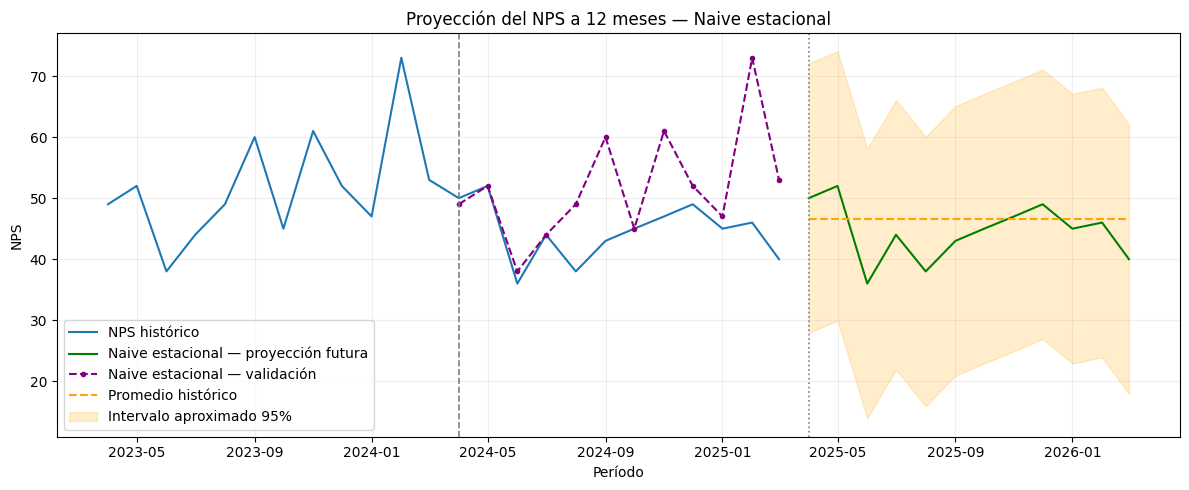

In [31]:
y_completo = serie_nps["NPS"]
indice_futuro = pd.date_range(
    start=serie_nps.index.max() + pd.offsets.MonthBegin(1),
    periods=12,
    freq="MS"
)
def generar_pronostico_final(nombre_modelo):
    if nombre_modelo == "Naive":
        valores = np.repeat(y_completo.iloc[-1], 12)
    elif nombre_modelo == "Promedio histórico":
        valores = np.repeat(y_completo.mean(), 12)
    elif nombre_modelo == "Naive estacional":
        valores = y_completo.iloc[-12:].to_numpy()
    elif nombre_modelo == "SES":
        modelo = SimpleExpSmoothing(
            y_completo, initialization_method="estimated"
        ).fit()
        valores = modelo.forecast(12).to_numpy()
    elif nombre_modelo == "Holt":
        modelo = Holt(
            y_completo, damped_trend=True, initialization_method="estimated"
        ).fit()
        valores = modelo.forecast(12).to_numpy()
    elif nombre_modelo == "Holt-Winters":
        modelo = ExponentialSmoothing(
            y_completo, trend="add", damped_trend=True,
            seasonal="add", seasonal_periods=12,
            initialization_method="estimated"
        ).fit()
        valores = modelo.forecast(12).to_numpy()
    elif nombre_modelo == "ARIMA(1,0,0) con tendencia":
        modelo = ARIMA(y_completo, order=(1, 0, 0), trend="t").fit()
        valores = modelo.forecast(12).to_numpy()
    elif nombre_modelo == "ARIMA(1,1,0)":
        modelo = ARIMA(y_completo, order=(1, 1, 0), trend="n").fit()
        valores = modelo.forecast(12).to_numpy()
    else:
        raise ValueError(f"Modelo no reconocido: {nombre_modelo}")
    return pd.Series(valores, index=indice_futuro, name="NPS proyectado")
modelo_seleccionado = modelo_corto_plazo
pronostico_final = generar_pronostico_final(modelo_seleccionado)
rmse_referencia = resultados_modelos.loc[
    (resultados_modelos["Modelo"] == modelo_seleccionado)
    & (resultados_modelos["Horizonte"] == 12),
    "RMSE"
].iloc[0]
proyeccion_final = pd.DataFrame({
    "NPS_proyectado": pronostico_final,
    "limite_inferior_aprox": pronostico_final - 1.96 * rmse_referencia,
    "limite_superior_aprox": pronostico_final + 1.96 * rmse_referencia
})
#proyeccion_final.round(2)
plt.figure(figsize=(12, 5))
proyeccion_promedio = pd.Series(
    np.repeat(y_completo.mean(), 12),
    index=pronostico_final.index
)
plt.plot(y_completo.index[-24:], y_completo.iloc[-24:], label="NPS histórico")
plt.plot(pronostico_final.index, pronostico_final, label="Naive estacional — proyección futura", color="green")
plt.plot(pronosticos_test["Naive estacional"].index, pronosticos_test["Naive estacional"], label="Naive estacional — validación", color="purple", linestyle="--", marker="o", markersize=3)
plt.plot(proyeccion_promedio.index, proyeccion_promedio, label="Promedio histórico", color="orange", linestyle="--")
plt.fill_between(
    proyeccion_final.index,
    proyeccion_final["limite_inferior_aprox"],
    proyeccion_final["limite_superior_aprox"],
    color="orange", alpha=0.2, label="Intervalo aproximado 95%"
)
plt.title(f"Proyección del NPS a 12 meses — {modelo_seleccionado}")
plt.xlabel("Período")
plt.ylabel("NPS")
plt.grid(alpha=0.2)
plt.axvline(test.index[0], color="gray", linestyle="--", linewidth=1.2)
plt.axvline(indice_futuro[0], color="gray", linestyle=":", linewidth=1.2)
y_max = plt.ylim()[1]
plt.legend(loc="lower left", ncol=1, frameon=True)
plt.tight_layout()
plt.show()


**Conclusión sobre los períodos**

- **Entrenamiento inicial:** 39 meses, desde enero de 2021 hasta marzo de 2024.
- **Validación:** 12 meses, desde abril de 2024 hasta marzo de 2025.
- **Ajuste final:** después de seleccionar el modelo, se vuelve a entrenar utilizando los 51 meses disponibles.
- **Predicción futura:** 12 meses, desde abril de 2025 hasta marzo de 2026.

La validación permite elegir el modelo con información que no fue utilizada durante el entrenamiento inicial. Luego, el modelo seleccionado se ajusta con todo el histórico para aprovechar la mayor cantidad de información posible antes de realizar la proyección futura.

**Conclusiones de la proyección anual**

- Se utilizará **Naive estacional** como modelo anual elegido, porque reproduce mejor las variaciones mensuales y es simple de actualizar.
- El **promedio histórico** obtiene un MAE menor a 12 meses, pero genera una línea constante y no refleja los cambios observados.
- Por decisión de negocio, se prioriza una proyección dinámica y fácil de interpretar, dejando el promedio histórico como referencia de comparación.

- **Implicancia para el negocio:** la proyección debe actualizarse mensualmente y complementarse con escenarios, ya que no representa un valor garantizado.


### Parte 3. Construir tres escenarios: Pesimista, Base y Optimista

**Flujo metodológico**

Histórico de drivers → Proyección individual de drivers → Escenarios Pesimista / Base / Optimista → Modelos Ridge y SARIMAX → Proyección del NPS → Comparación con la referencia univariada

En la Parte 2 se definió **Naive estacional** como referencia para proyectar el NPS sin drivers, porque es simple, se actualiza fácilmente y mantiene las variaciones mensuales observadas. En esta Parte 3 se construyen escenarios alternativos incorporando la evolución esperada de los drivers.

La Parte 3 combina dos etapas: primero se proyectan los drivers y luego se estima el NPS bajo distintos supuestos. Ridge funciona como un modelo de regresión, mientras que SARIMAX combina la dinámica temporal del NPS con los drivers. Estas proyecciones son condicionales: dependen de los valores supuestos para los drivers y no reemplazan la referencia de Naive estacional.

La comparación entre ambos enfoques permite distinguir la proyección esperada del NPS según su propio historial de los posibles resultados si los drivers mejoran o empeoran.


#### 3.1 Disponibilidad futura de los drivers

Para proyectar el NPS con variables explicativas es necesario conocer los valores futuros de los drivers. Por ejemplo, para predecir el NPS de junio sería necesario disponer también de `Driver_A`, `Driver_B`, `Driver_C` y `Driver_D` de junio. Sin embargo, al momento de realizar la proyección esos valores todavía no fueron observados.

En una evaluación retrospectiva los drivers del período de validación están disponibles porque esos meses ya forman parte del histórico. Esto permite medir cuánto explicarían los drivers si fueran conocidos, pero no reproduce una predicción real. Utilizarlos como si se conocieran anticipadamente produciría **data leakage** (fuga de información).

La disponibilidad también cambia con el tiempo. Por ejemplo, cuando termina junio ya se conocen los drivers de junio y pueden utilizarse para estimar julio. Sin embargo, para proyectar agosto o meses posteriores todavía sería necesario estimar los drivers futuros, salvo que la Universidad disponga de objetivos o proyecciones institucionales. Por eso, el modelo debería actualizarse mensualmente con un esquema de *rolling forecast*.

Para utilizarlos operativamente se pueden proyectar por separado, definir mediante escenarios o incorporar con rezagos conocidos. En esta sección se compararán Holt con tendencia amortiguada, ARIMA(1,0,0) y Naive estacional mediante una validación temporal. Se seleccionará el método con menor MAE para cada driver y se utilizará su pronóstico como escenario base. Luego, esos valores se modificarán para construir los escenarios Pesimista, Base y Optimista del NPS.

**Proyección futura de los drivers**

In [32]:
drivers = ["Driver_A", "Driver_B", "Driver_C", "Driver_D"]

indice_futuro = pd.date_range(
    start=serie_nps.index.max() + pd.offsets.MonthBegin(1),
    periods=12,
    freq="MS"
)

def pronosticar_driver(serie, metodo, horizonte):
    if metodo == "Holt amortiguado":
        return Holt(serie, damped_trend=True, initialization_method="estimated").fit().forecast(horizonte)
    if metodo == "ARIMA":
        return ARIMA(serie, order=(1, 0, 0)).fit().forecast(horizonte)
    return pd.Series(np.resize(serie.iloc[-12:].to_numpy(), horizonte))

metodos_driver = ["Holt amortiguado", "ARIMA", "Naive estacional"]
corte_driver = 6
evaluacion_drivers = []
seleccion_drivers = {}

for driver in drivers:
    serie_driver = serie_nps[driver].astype(float)
    entrenamiento = serie_driver.iloc[:-corte_driver]
    real = serie_driver.iloc[-corte_driver:].to_numpy()
    errores = {}
    for metodo in metodos_driver:
        pred = np.asarray(pronosticar_driver(entrenamiento, metodo, corte_driver), dtype=float)
        errores[metodo] = np.mean(np.abs(real - pred))
    mejor = min(errores, key=errores.get)
    seleccion_drivers[driver] = mejor
    evaluacion_drivers.append({"Driver": driver, **errores, "Método seleccionado": mejor})

tabla_seleccion_drivers = pd.DataFrame(evaluacion_drivers).set_index("Driver")
drivers_futuros_base = pd.DataFrame(index=indice_futuro)
for driver in drivers:
    drivers_futuros_base[driver] = np.asarray(pronosticar_driver(
        serie_nps[driver].astype(float), seleccion_drivers[driver], len(indice_futuro)
    ), dtype=float)

tabla_seleccion_drivers.round(2)

,Holt amortiguado,ARIMA,Naive estacional,Método seleccionado
Driver,,,,
Driver_A,4.59,9.26,4.83,Holt amortiguado
Driver_B,3.32,11.05,10.17,Holt amortiguado
Driver_C,3.39,5.87,5.67,Holt amortiguado
Driver_D,2.21,3.85,4.67,Holt amortiguado


**Conclusión:** Holt amortiguado obtuvo el menor MAE para los cuatro drivers, por lo que se utilizará como método base. Esto confirma que, con la información disponible, las tendencias recientes ofrecen la referencia más confiable para proyectar los indicadores. Como implicancia de negocio, los escenarios del NPS se construirán sobre una estimación validada y no sobre una elección arbitraria del método.

#### 3.2 Modelos con drivers: proyección del NPS

En la **sección 3.1** se proyecta cada driver individualmente, utilizando únicamente su propio historial. El resultado son valores futuros estimados para `Driver_A`, `Driver_B`, `Driver_C` y `Driver_D`.

En esta sección se utilizan esas proyecciones de los drivers como variables explicativas para estimar el NPS futuro. Es decir, aquí se modela la relación conjunta entre los drivers y el NPS. Se entrenan dos alternativas con todo el histórico disponible:

- **Ridge:** modelo de regresión regularizada que estima el NPS a partir de los cuatro drivers y reduce el impacto de la multicolinealidad.
- **SARIMAX con variables exógenas:** combina el comportamiento histórico del NPS con los drivers proyectados. También incorpora los efectos de meses anteriores, una tendencia temporal y posibles patrones estacionales. Se utiliza como alternativa para comparar sus resultados con Ridge.

Estos modelos no proyectan los drivers; reciben como entrada las proyecciones generadas en 3.1 y devuelven una proyección del NPS. Luego, en las secciones siguientes, los valores de los drivers se modifican para representar los escenarios **Pesimista, Base y Optimista**. Por lo tanto, la secuencia es: **proyectar drivers → aplicar modelos NPS → comparar escenarios**.

In [33]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from statsmodels.tsa.statespace.sarimax import SARIMAX

modelo_ridge_drivers = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)
modelo_ridge_drivers.fit(serie_nps[drivers], serie_nps["NPS"])

modelo_sarimax_drivers = SARIMAX(
    serie_nps["NPS"],
    exog=serie_nps[drivers],
    order=(1, 0, 0),
    trend="t",
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

def componentes_mensuales(indice):
    mes = indice.month
    return pd.DataFrame({
        "mes_sin": np.sin(2 * np.pi * mes / 12),
        "mes_cos": np.cos(2 * np.pi * mes / 12)
    }, index=indice)

drivers_hist_lag = serie_nps[drivers].shift(1).add_suffix("_lag1")
tendencia_hist = pd.DataFrame({"tendencia": np.arange(len(serie_nps))}, index=serie_nps.index)
exog_hist_estacional = pd.concat([serie_nps[drivers], drivers_hist_lag, tendencia_hist, componentes_mensuales(serie_nps.index)], axis=1).dropna()
drivers_completos = pd.concat([serie_nps[drivers].tail(1), drivers_futuros_base])
drivers_futuro_lag = drivers_completos.shift(1).iloc[1:].set_axis(indice_futuro).add_suffix("_lag1")
tendencia_futura = pd.DataFrame({"tendencia": np.arange(len(serie_nps), len(serie_nps) + len(indice_futuro))}, index=indice_futuro)
exog_futuro_estacional = pd.concat([drivers_futuros_base, drivers_futuro_lag, tendencia_futura, componentes_mensuales(indice_futuro)], axis=1)
modelo_sarimax_estacional = SARIMAX(
    serie_nps.loc[exog_hist_estacional.index, "NPS"], exog=exog_hist_estacional, order=(1, 0, 0), trend="t",
    enforce_stationarity=False, enforce_invertibility=False
).fit(disp=False)

proyeccion_sarimax_estacional = modelo_sarimax_estacional.get_forecast(
    steps=len(indice_futuro), exog=exog_futuro_estacional
).predicted_mean

proyecciones_base_drivers = pd.DataFrame({
    "Ridge": modelo_ridge_drivers.predict(drivers_futuros_base),
    "SARIMAX": modelo_sarimax_estacional.get_forecast(
        steps=12,
        exog=exog_futuro_estacional
    ).predicted_mean.to_numpy()
}, index=indice_futuro)

proyecciones_base_drivers.round(2)

c:\Users\ithre\Documents\Yani\Trabajos\Siglo21\Challenge\environment\siglo21\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\ithre\Documents\Yani\Trabajos\Siglo21\Challenge\environment\siglo21\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


,Ridge,SARIMAX
2025-04-01,50.95,39.36
2025-05-01,51.13,37.51
2025-06-01,51.29,37.31
2025-07-01,51.42,38.16
2025-08-01,51.54,39.90
2025-09-01,51.64,42.07
2025-10-01,51.73,44.06
2025-11-01,51.80,45.30
2025-12-01,51.87,45.38
2026-01-01,51.93,44.21


#### 3.3 Definición de los escenarios

Los escenarios se construyen modificando gradualmente las proyecciones de los drivers: 5% al inicio y hasta 10% al final del horizonte.

- **Pesimista:** los drivers se deterioran respecto de su proyección base.
- **Base:** se mantienen las proyecciones centrales de los drivers.
- **Optimista:** los drivers mejoran respecto de su proyección base.

Los porcentajes son supuestos ilustrativos y deben validarse con Dirección. Los valores se limitan al rango observado del dataset.

In [34]:
shock_escenario = 0.05
limites_min = serie_nps[drivers].min()
limites_max = serie_nps[drivers].max()

drivers_escenarios = {
    "Pesimista": (drivers_futuros_base * (1 - shock_escenario)).clip(
        lower=limites_min, upper=limites_max, axis=1
    ),
    "Base": drivers_futuros_base.copy(),
    "Optimista": (drivers_futuros_base * (1 + shock_escenario)).clip(
        lower=limites_min, upper=limites_max, axis=1
    )
}

drivers_escenarios["Base"].head()

,Driver_A,Driver_B,Driver_C,Driver_D
2025-04-01,90.14,96.00,86.35,85.60
2025-05-01,90.19,96.65,86.46,85.60
2025-06-01,90.22,97.28,86.56,85.60
2025-07-01,90.25,97.88,86.64,85.60
2025-08-01,90.27,98.47,86.70,85.60


#### 3.5 Comparación final de modelos

Los escenarios utilizan shocks progresivos sobre los drivers para evitar cambios bruscos y representar una evolución gradual. La trayectoria Base se calibra sobre Naive estacional, mientras que Ridge y SARIMAX aportan los ajustes asociados a los drivers.

La comparación entre Ridge y SARIMAX permite evaluar si los resultados dependen demasiado del modelo utilizado.

In [35]:
multiplicador_pesimista = np.linspace(0.95, 0.90, len(indice_futuro))
multiplicador_optimista = np.linspace(1.05, 1.10, len(indice_futuro))

drivers_escenarios_dinamicos = {
    "Pesimista": drivers_futuros_base.mul(multiplicador_pesimista, axis=0).clip(lower=limites_min, upper=limites_max, axis=1),
    "Base": drivers_futuros_base.copy(),
    "Optimista": drivers_futuros_base.mul(multiplicador_optimista, axis=0).clip(lower=limites_min, upper=limites_max, axis=1)
}

naive_estacional_futuro = pd.Series([serie_nps.loc[fecha - pd.DateOffset(years=1), "NPS"] for fecha in indice_futuro], index=indice_futuro)
proyecciones_sin_calibrar = {}
for escenario, drivers_futuros in drivers_escenarios_dinamicos.items():
    proyecciones_sin_calibrar[("Ridge", escenario)] = modelo_ridge_drivers.predict(drivers_futuros)
    drivers_completos = pd.concat([serie_nps[drivers].tail(1), drivers_futuros])
    drivers_lag = drivers_completos.shift(1).iloc[1:].set_axis(indice_futuro).add_suffix("_lag1")
    tendencia = pd.DataFrame({"tendencia": np.arange(len(serie_nps), len(serie_nps) + len(indice_futuro))}, index=indice_futuro)
    exog_escenario = pd.concat([drivers_futuros, drivers_lag, tendencia, componentes_mensuales(indice_futuro)], axis=1)
    proyecciones_sin_calibrar[("SARIMAX", escenario)] = modelo_sarimax_estacional.get_forecast(steps=len(indice_futuro), exog=exog_escenario).predicted_mean.to_numpy()

proyecciones_modelos = {}
for modelo in ["Ridge", "SARIMAX"]:
    base_modelo = pd.Series(proyecciones_sin_calibrar[(modelo, "Base")], index=indice_futuro)
    for escenario in ["Pesimista", "Base", "Optimista"]:
        valor_modelo = pd.Series(proyecciones_sin_calibrar[(modelo, escenario)], index=indice_futuro)
        proyecciones_modelos[(modelo, escenario)] = naive_estacional_futuro + (valor_modelo - base_modelo)
proyecciones_modelos = pd.DataFrame(proyecciones_modelos, index=indice_futuro)
proyecciones_modelos.round(2)


Ridge                   SARIMAX                
           Pesimista  Base Optimista Pesimista  Base Optimista
2025-04-01     43.02 50.00     57.08     44.71 50.00     53.77
2025-05-01     44.38 52.00     59.76     48.39 52.00     55.77
2025-06-01     27.73 36.00     44.43     32.11 36.00     40.16
2025-07-01     35.09 44.00     53.11     39.83 44.00     48.55
2025-08-01     28.44 38.00     47.78     33.56 38.00     42.93
2025-09-01     32.80 43.00     53.46     38.28 43.00     48.30
2025-10-01     34.15 45.00     56.14     40.00 45.00     50.67
2025-11-01     35.51 47.00     58.81     41.73 47.00     53.04
2025-12-01     36.87 49.00     61.49     43.46 49.00     55.41
2026-01-01     32.22 45.00     58.16     39.19 45.00     51.77
2026-02-01     32.58 46.00     59.46     39.91 46.00     53.14
2026-03-01     25.93 40.00     53.50     33.64 40.00     47.37

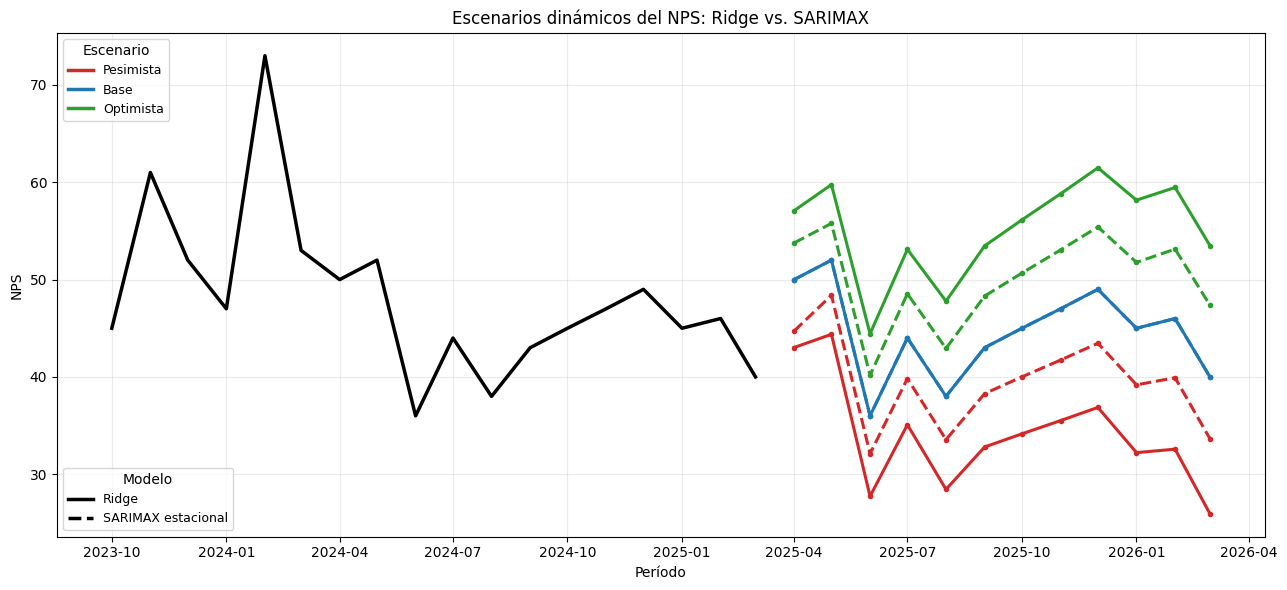

In [36]:
fig, ax = plt.subplots(figsize=(13, 6))
ax.plot(serie_nps.index[-18:], serie_nps["NPS"].tail(18),
        color="black", linewidth=2.5, label="NPS histórico")

colores = {"Pesimista": "#d62728", "Base": "#1f77b4", "Optimista": "#2ca02c"}
estilos = {"Ridge": "-", "SARIMAX": "--"}
for (modelo, escenario), valores in proyecciones_modelos.items():
    ax.plot(
        indice_futuro, valores,
        color=colores[escenario], linestyle=estilos[modelo],
        linewidth=2.2, marker="o", markersize=3,
        label=f"{escenario} — {modelo}"
    )

ax.set_title("Escenarios dinámicos del NPS: Ridge vs. SARIMAX")
ax.set_xlabel("Período")
ax.set_ylabel("NPS")
ax.grid(alpha=0.25)
from matplotlib.lines import Line2D
leyenda_escenarios = [
    Line2D([0], [0], color=colores[escenario], lw=2.5, label=escenario)
    for escenario in ["Pesimista", "Base", "Optimista"]
]
leyenda_modelos = [
    Line2D([0], [0], color="black", lw=2.5, linestyle="-", label="Ridge"),
    Line2D([0], [0], color="black", lw=2.5, linestyle="--", label="SARIMAX estacional")
]
leyenda1 = ax.legend(handles=leyenda_escenarios, title="Escenario", loc="upper left", fontsize=9)
ax.add_artist(leyenda1)
ax.legend(handles=leyenda_modelos, title="Modelo", loc="lower left", fontsize=9)
plt.tight_layout()
plt.show()

**Conclusiones de los diferentes escenarios**

- La trayectoria **Base** parte de Naive estacional y mantiene una evolución mensual, evitando una proyección constante.
- El escenario **Pesimista** muestra cómo podría disminuir el NPS si los drivers se deterioran.
- El escenario **Optimista** muestra el resultado potencial si los drivers mejoran.
- Ridge y SARIMAX aportan ajustes sobre la misma referencia; sus diferencias reflejan incertidumbre sobre la relación entre drivers y NPS.

**Implicancia para el negocio:** conviene usar Naive estacional como referencia operativa y los escenarios para anticipar riesgos, establecer objetivos y priorizar acciones.

### 3.6 Conclusión ejecutiva y decisiones recomendadas

- Para los próximos 3, 6 y 12 meses se utilizará **Naive estacional** como referencia, ya que mantiene una trayectoria dinámica y es simple de actualizar.
- Los escenarios con drivers se interpretan como alternativas condicionales: muestran qué podría ocurrir si los drivers empeoran, se mantienen o mejoran.
- La trayectoria Base de los escenarios se calibra sobre Naive estacional; Ridge y SARIMAX aportan los ajustes vinculados a los drivers.
- Las proyecciones deben actualizarse mensualmente con los nuevos datos observados.

**Implicancia para el negocio:** se recomienda monitorear el NPS y los drivers, comparar la evolución real con los tres escenarios y definir acciones para acercarse al escenario optimista.

#### 4.1 Limitaciones de los datos

Esta sección resume las limitaciones de todo el enfoque. Incluye tanto los modelos de forecasting univariado utilizados en la Parte 2 como los modelos con drivers y escenarios desarrollados en la Parte 3.

- El dataset tiene 51 observaciones mensuales, por lo que la cantidad de información es limitada para estimar tendencias y estacionalidad con mucha precisión.
- El horizonte de necesidad de proyección no está definido. Esto es importante porque el modelo con mejor desempeño puede cambiar según el horizonte: un método puede funcionar mejor a 3 meses y otro a 12 meses. También cambia la incertidumbre y el tipo de decisión que se puede apoyar. Por eso se evaluaron horizontes de 3, 6 y 12 meses, pero sería necesario confirmar con el negocio cuál de ellos es prioritario.
- No se conocen los valores futuros reales de los drivers. Por eso, deben proyectarse y los resultados dependen de esos supuestos.
- No se dispone de información adicional sobre cantidad de respuestas, composición de los estudiantes o cambios institucionales que puedan afectar el NPS.
- En la Parte 2, los modelos solo utilizan el historial del NPS y no incorporan factores externos. En la Parte 3, sí se incorporan drivers, pero sus valores futuros deben ser estimados.

#### 4.2 Riesgos del enfoque

- Las relaciones entre drivers y NPS no demuestran causalidad. Una correlación alta no significa que un driver provoque por sí solo cambios en el NPS.
- Las proyecciones pueden perder precisión si ocurre un cambio importante en la Universidad o en el contexto.
- En este análisis, Ridge y SARIMAX produjeron resultados diferentes. Ridge generó trayectorias más estables, mientras que SARIMAX mostró mayor variación al incorporar la dinámica temporal, los rezagos y la estacionalidad. Esto significa que la elección del modelo puede cambiar la proyección del NPS y, por lo tanto, las decisiones basadas en ella. No alcanza con elegir el modelo que produzca el gráfico más variable: es necesario compararlos con validación temporal y métricas de error, como MAE y RMSE.
- Aunque los drivers presentan una relación positiva con el NPS en el análisis general, una mejora mensual en un driver no siempre se traduce en un aumento inmediato del NPS. Esto puede deberse a efectos rezagados, otros factores no observados o diferencias entre segmentos. Por lo tanto, no debe asumirse que mejorar un driver producirá automáticamente una mejora equivalente en el NPS.
- Los escenarios no deben interpretarse como predicciones exactas, sino como referencias para analizar posibles situaciones.

#### 4.3 Supuestos utilizados

- La frecuencia mensual y el orden temporal de los datos son correctos.
- Los valores futuros de los drivers pueden aproximarse utilizando su comportamiento histórico.
- El escenario Base representa la trayectoria central de los drivers.
- Los escenarios Pesimista y Optimista representan variaciones razonables respecto del escenario Base.
- La relación estimada entre los drivers y el NPS se mantiene durante el horizonte proyectado.

#### 4.4 Recomendaciones para mejorar el enfoque

- Para la Parte 2, continuar comparando los modelos univariados en horizontes de 3, 6 y 12 meses y seleccionar el modelo según el plazo que sea prioritario para el negocio.
- Para la Parte 2, actualizar el modelo cada mes y volver a calcular el MAE y el RMSE con los nuevos valores observados.
- Para la Parte 3, validar con Dirección los porcentajes utilizados para construir los escenarios y definir valores diferentes para cada driver cuando corresponda.
- Para la Parte 3, contrastar Ridge y SARIMAX con backtesting y conservar el modelo que tenga menor error en el horizonte seleccionado.
- Comparar las proyecciones mensuales con los resultados reales y ajustar los supuestos cuando el error sea persistentemente alto.
- Incorporar intervalos de predicción para comunicar un rango probable de NPS y no únicamente un valor puntual.
- Agregar más meses de información antes de utilizar modelos más complejos, ya que el dataset actual tiene pocas observaciones para estimar muchos parámetros.

## Entregables

1. Notebook con el desarrollo completo.
2. Informe ejecutivo de máximo 3 páginas dirigido a Dirección.
3. Principales recomendaciones para mejorar la capacidad predictiva futura.

## Pregunta adicional

Si dispusieras de seis meses para mejorar la capacidad predictiva del modelo, ¿qué nuevas variables o fuentes de información incorporarías y por qué?

### Principales recomendaciones para mejorar la capacidad predictiva futura

Incorporaría información que permita explicar mejor por qué cambia el NPS y que también esté disponible antes de realizar una nueva proyección.

- **Respuestas individuales, universo y representatividad:** permitirían conocer cuántos estudiantes podían responder, cuántos respondieron y cómo se distribuyen por carrera, sede, modalidad y año de cursada. Actualmente no sabemos si cada fila representa a toda la población estudiantil o únicamente a quienes respondieron la encuesta. Esta información permitiría analizar la variabilidad, detectar sesgos de cobertura y ponderar mejor el NPS mensual.
- **Cantidad de respuestas y tasa de respuesta:** ayudarían a medir la confiabilidad de cada valor mensual del NPS.
- **Información académica y administrativa:** como inscripciones, bajas, regularidad, tiempos de respuesta y uso de servicios institucionales.
- **Interacciones con los canales de atención:** cantidad de consultas, reclamos, tiempos de resolución y temas más frecuentes.
- **Calendario institucional:** inicio y cierre de períodos, inscripciones, exámenes y otros eventos que podrían generar cambios estacionales.
- **Variables segmentadas:** permitirían detectar grupos con experiencias diferentes y orientar mejor las acciones. Por ejemplo, el NPS podría analizarse por carrera, sede, modalidad de cursada, año de ingreso o condición de estudiante. Si el NPS fuera menor en estudiantes de primer año o en una sede específica, la Universidad podría diseñar acciones focalizadas en esos grupos en lugar de aplicar una medida general. También permitiría identificar qué drivers son más importantes para cada segmento.

También incorporaría variables más específicas para entender mejor las diferencias entre estudiantes:

- **Nivel de avance en la carrera:** comparar estudiantes iniciales, intermedios y próximos a graduarse.
- **Rendimiento académico:** considerar promedio, materias aprobadas y materias recursadas.
- **Tipo de cursada:** diferenciar modalidades presencial, virtual e híbrida.
- **Uso de plataformas digitales:** frecuencia de ingreso al campus y participación en actividades.
- **Interacciones con la Universidad:** cantidad de consultas, reclamos, solicitudes y tiempos de respuesta.
- **Participación institucional:** asistencia a tutorías, eventos y actividades extracurriculares.
- **Situación laboral y ubicación:** distinguir estudiantes que trabajan, estudian a tiempo completo o cursan a distancia.
- **Calendario académico:** identificar posibles cambios durante inscripciones, exámenes y cierre de períodos.

Durante esos seis meses también realizaría un proceso de validación continua: incorporaría los nuevos datos, compararía distintos modelos y revisaría las proyecciones contra los resultados reales. De esta manera, el modelo no solo tendría más variables, sino también una mejor base para tomar decisiones.

## Aclaraciones

- Puede utilizarse cualquier metodología analítica o estadística.
- Se valorará la justificación de las decisiones tomadas.
- No se evaluará únicamente la precisión del modelo, sino también la comprensión del problema de negocio.